# 01 · Data understanding

Week 4 of the roadmap (`feat/data-understanding` in `TODO.md`). The goal is
to know the Arena daily bars well enough to settle four open choices before
the forecaster is improved:

1. which price jumps void a label (price limits, unadjusted corporate
   actions, copied bars);
2. the sideways band θ;
3. the start of the sample (2020 or 2023);
4. the VN30 list.

Every check prints a short summary and asserts the numbers it relies on, so
a re-run on newer data fails loudly if a conclusion no longer holds.
Decisions are collected in the last section and recorded in
`docs/strategy/README.md` (sections 5–6).

Run from the repository root with
`jupyter execute --inplace notebooks/01_data_understanding.ipynb`.

In [1]:
import dataclasses

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from market_radar import pipeline
from market_radar.config import find_root, load_settings
from market_radar.data.quality import (
    close_returns_pct,
    quality_report,
    range_breaches,
    repeated_bars,
    suspect_moves,
)
from market_radar.forecaster.evaluate import (
    diebold_mariano,
    score_rows,
    walk_forward_predictions,
)
from market_radar.forecaster.labels import add_labels, classify_return
from market_radar.forecaster.walk_forward import walk_forward_folds

ROOT = find_root()
FIGURES = ROOT / "docs" / "figures" / "data_understanding"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 120)

# Chart colours: blue/red diverging pair with a neutral grey midpoint.
UP_COLOR, DOWN_COLOR, FLAT_COLOR = "#2a78d6", "#e34948", "#c3c2b7"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
})

## 1. Overview

The panel is what the forecaster sees: stored Arena bars for 76 symbols
(VNINDEX, VN30 and 74 stocks) plus the synthetic BANKS basket. `MCH` and `VPL` are VN30 members without Arena
bars.

In [2]:
settings = load_settings(ROOT)
universe = settings.universe
data = pipeline.load_market_data(settings)
raw = data.bars[data.bars["source"] != "basket"].reset_index(drop=True)
sessions = data.calendar.sessions

missing = sorted(set(universe.fetch_symbols) - set(raw["symbol"]))
rows_per_symbol = raw.groupby("symbol").size()
print(f"Symbols with bars: {raw['symbol'].nunique()} "
      f"(missing: {', '.join(missing)})")
print(f"Sessions: {sessions[0].date()} to {sessions[-1].date()} "
      f"({len(sessions)})")
print(f"Bars: {len(raw):,}; per symbol min {rows_per_symbol.min()}, "
      f"median {rows_per_symbol.median():.0f}, max {rows_per_symbol.max()}")
assert missing == ["MCH", "VPL"], missing

Symbols with bars: 76 (missing: MCH, VPL)
Sessions: 2019-01-02 to 2026-11-17 (1965)
Bars: 144,645; per symbol min 268, median 1965, max 1965


## 2. Coverage and quality

`quality_report` counts, per symbol, sessions missing between its first
and last bar, duplicate dates, inconsistent OHLC rows, moves beyond the
price limit of the day, highs or lows beyond the ceiling or floor of the
day, and bars copied from the previous session.

In [3]:
def summarise_quality(report: pd.DataFrame) -> pd.DataFrame:
    """Keep the symbols that have at least one quality problem.

    Args:
        report: Output of ``quality_report``.

    Returns:
        Problem columns of the affected symbols, worst first.
    """
    problems = ["missing_sessions", "duplicate_dates", "bad_ohlc",
                "limit_breaches", "range_breaches", "repeated_bars"]
    flagged = report[report[problems].sum(axis=1) > 0]
    order = flagged[problems].sum(axis=1).sort_values(ascending=False)
    return flagged.loc[order.index, ["symbol", *problems]]


report = quality_report(raw, sessions, universe)
flagged = summarise_quality(report)
totals = report[["missing_sessions", "duplicate_dates", "bad_ohlc",
                 "limit_breaches", "range_breaches",
                 "repeated_bars"]].sum()
print("Totals:", totals.to_dict())
print(f"Volume coverage: {report['volume_coverage'].max():.0%} "
      "(Arena has no volume)")
print(flagged.head(10).to_string(index=False))
assert totals["duplicate_dates"] == 0
assert report["volume_coverage"].max() == 0.0
bad_ohlc = report.set_index("symbol")["bad_ohlc"]
assert bad_ohlc.idxmax() == "HHV" and bad_ohlc.sum() < 100, bad_ohlc.sum()

Totals: {'missing_sessions': 95, 'duplicate_dates': 0, 'bad_ohlc': 75, 'limit_breaches': 34, 'range_breaches': 34, 'repeated_bars': 686}
Volume coverage: 0% (Arena has no volume)
symbol  missing_sessions  duplicate_dates  bad_ohlc  limit_breaches  range_breaches  repeated_bars
   HHV                 9                0        47               6               3            411
   VIX                 7                0         0               0               0             38
   ABB                 0                0         0               0               3             41
   LPB                 3                0         0               0               1             30
   IDC                 6                0         5               0               2             18
   VND                 6                0         1              13               8              0
   BVB                 8                0         0               2               0             18
   SHB                 3     

In [4]:
def bad_ohlc_rows(bars: pd.DataFrame) -> pd.DataFrame:
    """Return the bars whose open, high, low and close are inconsistent.

    Args:
        bars: Long bars sorted by symbol and date.

    Returns:
        The offending rows.
    """
    body_high = bars[["open", "close"]].max(axis=1)
    body_low = bars[["open", "close"]].min(axis=1)
    bad = (bars["high"] < body_high - 1e-9) | (bars["low"] > body_low + 1e-9)
    return bars[bad]


bad_rows = bad_ohlc_rows(raw)
recent = bad_rows[bad_rows["date"] >= "2023-01-01"]
print("Bad OHLC rows by year:",
      bad_rows.groupby(bad_rows["date"].dt.year).size().to_dict())
print(recent[["symbol", "date", "open", "high", "low", "close"]]
      .to_string(index=False))
assert len(recent) <= 10, len(recent)

Bad OHLC rows by year: {2019: 34, 2020: 22, 2021: 9, 2022: 2, 2025: 8}
symbol       date  open  high   low  close
   IDC 2025-05-14 30.96 31.32 31.32  31.32
   MBS 2025-05-14 18.01 18.34 18.34  18.34
   MBS 2025-05-15 18.34 18.47 18.47  18.47
   PVS 2025-05-15 21.88 21.73 21.73  21.73
   PVS 2025-05-19 21.42 21.11 21.11  21.11
   SHS 2025-05-14 12.00 12.29 12.29  12.29
   SHS 2025-05-16 12.58 12.29 12.29  12.29
   SHS 2025-05-19 12.48 12.20 12.20  12.20


In [5]:
ranges = range_breaches(raw, universe)
recent_ranges = ranges[ranges["date"] >= "2023-01-01"]
print(f"Highs or lows beyond the ceiling or floor: {len(ranges)} rows")
print("By year:", ranges.groupby(ranges["date"].dt.year).size().to_dict())
print(recent_ranges.to_string(index=False))
assert len(ranges) < 100 and len(recent_ranges) <= 10, (
    len(ranges), len(recent_ranges))


Highs or lows beyond the ceiling or floor: 34 rows
By year: {2019: 7, 2020: 7, 2021: 15, 2022: 1, 2024: 1, 2025: 2, 2026: 1}
symbol       date  high_pct  low_pct  limit_pct
   EIB 2025-05-23      8.15     5.19        7.0
   VGI 2024-06-27      1.87   -15.71       15.0
   VGI 2025-10-29      0.00   -15.60       15.0
   VGI 2026-03-02      0.00   -15.55       15.0


**Reading.** The data are complete: there are no duplicate dates and
almost no gaps. The few missing sessions are stocks suspended for a few
days.

Inconsistent OHLC rows are rare (under 0.1% of bars):
- most come from HHV, an illiquid UPCoM stock, in 2019–2020;
- since 2023 there are only eight rows, on HNX stocks in mid-May 2025,
  where the open lies outside a high–low range that has collapsed onto the
  close.

Highs or lows beyond the ceiling or floor of the day (with the close
inside the limit) are just as rare. This check found one more transfer:
IDC traded on UPCoM until 2019-11-29 and on HNX from 2019-12-10, so its
2019 highs of 11–13% were legal; it is now in `exchange_history`. The
remaining rows fall mostly in 2019–2021 (illiquid stocks before a
transfer, VND around its 2021 corporate actions, where the bars are only
partly adjusted). Since 2023 there are four rows: EIB on 2025-05-23 and
three VGI lows on UPCoM a fraction beyond −15%, about the size of the
back-adjustment error.

Labels use closes only, so these rows affect a few range features and
nothing else; they are reported, not voided. Arena carries no volume, so the liquidity signals stay off.

## 3. Exchange transfers

HOSE allows ±7% a day, HNX ±10% and UPCoM ±15%. Until this week every stock
was checked against its *current* exchange, so a stock that moved to HOSE
saw its earlier, legal 8–15% days flagged as suspect and their labels
voided. The table shows the largest daily move per year for the stocks
whose large moves stop at a date; that date matches the transfer reported
in the press (`exchange_history` in `config/universe.yaml`).

In [6]:
def max_move_by_year(bars: pd.DataFrame, symbols: list[str]) -> pd.DataFrame:
    """Largest absolute daily close-to-close move per symbol and year.

    Args:
        bars: Long bars sorted by symbol and date.
        symbols: Symbols to keep.

    Returns:
        Symbols by years, in percent, rounded to one decimal.
    """
    moves = bars.assign(ret=close_returns_pct(bars).abs(),
                        year=bars["date"].dt.year)
    moves = moves[moves["symbol"].isin(symbols)]
    return moves.pivot_table(index="symbol", columns="year", values="ret",
                             aggfunc="max").round(1)


transferred = sorted(universe.exchange_history)
table = max_move_by_year(raw, transferred)
history = pd.DataFrame([
    {"symbol": symbol, "earlier": listing.exchange,
     "last_session": listing.until}
    for symbol, listings in universe.exchange_history.items()
    for listing in listings
]).set_index("symbol")
print(table.join(history).to_string())

        2019  2020  2021  2022  2023  2024  2025  2026 earlier last_session
symbol                                                                     
ACB      3.7   9.8  19.7   6.9   4.0   5.9   7.0   6.9     HNX   2020-12-01
BCM      9.6  13.6   7.0   7.0   6.9   7.0   7.0   7.0   UPCOM   2020-08-19
BSR      9.8  13.5  12.9  12.8   6.9   8.1   7.0   7.0   UPCOM   2025-01-06
CTR     14.3  14.9  21.9   7.0   7.0   7.0   7.0   7.0   UPCOM   2022-02-14
DGC      9.9   8.1   7.0   7.0   7.0   7.0   7.0   7.0     HNX   2020-07-17
GVR     10.6  10.4   7.0   7.1   7.0   7.0   7.0   7.0   UPCOM   2020-03-06
HHV     24.4  24.1  15.9   7.0   7.0   7.0   7.0   6.9   UPCOM   2022-01-06
IDC     12.5  10.0  10.0  10.0   9.6   5.7  10.0   9.9   UPCOM   2019-11-29
LPB      6.3  15.4   7.0   7.0   7.0   6.9   7.0   7.0   UPCOM   2020-10-23
NAB      NaN   8.3  14.3  11.7   8.2   6.9   7.0   6.9   UPCOM   2024-02-28
SHB      6.7  10.2  10.0   7.2   6.8   5.7   7.0   6.9     HNX   2021-10-05
VCG      9.9

In [7]:
def label_voids(panel: pd.DataFrame, suspect: pd.DataFrame | None,
                start: str) -> dict[int, int]:
    """Count labels voided by a set of suspect bars.

    Args:
        panel: Rows ``symbol``, ``date`` and ``close``.
        suspect: Suspect ``symbol``/``date`` pairs, or None.
        start: First label date counted.

    Returns:
        Horizon to number of voided labels (labels whose window ends after
        the last bar are not counted).
    """
    base = add_labels(panel, settings.labels.horizons,
                      settings.labels.sideway_band_pct, None)
    labelled = add_labels(panel, settings.labels.horizons,
                          settings.labels.sideway_band_pct, suspect)
    keep = base["date"] >= start
    return {
        h: int((base.loc[keep, f"label_{h}"].notna()
                & labelled.loc[keep, f"label_{h}"].isna()).sum())
        for h in settings.labels.horizons
    }


closes = data.panel[["symbol", "date", "close"]]
old_universe = dataclasses.replace(universe, exchange_history={})
old_rule = suspect_moves(data.bars, old_universe)
new_limit = data.suspect[data.suspect["reason"] == "limit"]
comparison = pd.DataFrame({
    "suspect bars": [len(old_rule), len(new_limit)],
    "voided 2020+ (h=1)": [label_voids(closes, old_rule, "2020-01-01")[1],
                           label_voids(closes, new_limit, "2020-01-01")[1]],
    "voided 2020+ (h=5)": [label_voids(closes, old_rule, "2020-01-01")[5],
                           label_voids(closes, new_limit, "2020-01-01")[5]],
}, index=["current exchange only", "exchange of the day"])
print(comparison.to_string())
assert len(new_limit) < len(old_rule) / 5, (len(new_limit), len(old_rule))

                       suspect bars  voided 2020+ (h=1)  voided 2020+ (h=5)
current exchange only           340                 283                1013
exchange of the day              37                  34                 145


**Reading.** Using the exchange of the day removes almost nine in ten
"suspect" moves. The fixed moves were real trading on HNX or UPCoM, and
their labels were wrongly voided. All of these transfers happened before
2023 except NAB (2024) and BSR (2025), so the fix matters most if the sample
starts earlier (section 7).

Two transfers are still to come and are **not** in the config yet:
- every HNX stock (SHS, MBS, PVS, IDC here) moves to HOSE on 2026-12-28;
- the price limit they will trade with has not been published.

## 4. Price adjustment and remaining jumps

Arena's prices are **back-adjusted** for most dividends. For the median
stock, 60% of closes before 2026 do not sit on the HOSE price grid (ticks
of 10, 50 or 100 VND). STB, which paid no dividend from 2019 to 2026, is on the
grid throughout. Adjustment is **not** complete, though. The moves still
beyond the limit of the day are ex-dates that were left unadjusted.

In [8]:
def off_grid_share(bars: pd.DataFrame) -> pd.Series:
    """Share of closes that are not on the HOSE tick grid, per symbol.

    Args:
        bars: Long bars of stocks (prices in thousand VND).

    Returns:
        Share in [0, 1] per symbol for bars before 2026.
    """
    early = bars[bars["date"] < "2026-01-01"]
    vnd = (early["close"] * 1000).round(3)
    tick = np.select([vnd < 10_000, vnd < 50_000], [10, 50], 100)
    off = np.abs(vnd / tick - np.round(vnd / tick)) > 1e-6
    return pd.Series(off, index=early.index).groupby(early["symbol"]).mean()


stocks = raw[~raw["symbol"].isin(universe.indices)]
off_grid = off_grid_share(stocks)
print(f"Median off-grid share before 2026: {off_grid.median():.0%}; "
      f"STB: {off_grid['STB']:.0%}")
assert off_grid.median() > 0.5 and off_grid["STB"] == 0.0

Median off-grid share before 2026: 60%; STB: 0%


In [9]:
KNOWN_EVENTS = {
    ("ACB", "2021-06-10"): "25% stock dividend (record date 2021-06-11)",
    ("VND", "2021-06-10"): "1:1 rights issue at 14,500 VND",
    ("TCX", "2026-09-16"): "5:1 stock dividend (ex-date 2026-09-17 in press)",
    ("FPT", "2026-09-18"): "10:1 bonus shares (record date 2026-09-22)",
}


def describe_jumps(suspect: pd.DataFrame) -> pd.DataFrame:
    """Attach the verified corporate action to each remaining jump.

    Args:
        suspect: Output of ``suspect_moves``.

    Returns:
        The jumps with an ``event`` column (empty when not looked up).
    """
    days = suspect["date"].dt.strftime("%Y-%m-%d")
    keys = zip(suspect["symbol"], days, strict=True)
    events = [KNOWN_EVENTS.get(key, "") for key in keys]
    return suspect.assign(event=events)


jumps = describe_jumps(suspect_moves(raw, universe))
by_year = jumps.groupby(jumps["date"].dt.year).size().to_dict()
print(f"Jumps beyond the limit of the day: {len(jumps)}; by year {by_year}")
print(jumps[jumps["date"] >= "2021-01-01"].to_string(index=False))
assert len(jumps) < 50

Jumps beyond the limit of the day: 34; by year {2019: 3, 2020: 3, 2021: 24, 2025: 1, 2026: 3}
symbol       date  ret_pct  limit_pct                                            event
   ACB 2021-06-10   -19.65        7.0      25% stock dividend (record date 2021-06-11)
   BVB 2025-04-08   -15.76       15.0                                                 
   CTR 2021-01-29    16.06       15.0                                                 
   CTR 2021-06-23   -21.90       15.0                                                 
   DIG 2021-06-08   -17.14        7.0                                                 
   FPT 2021-06-01   -11.03        7.0                                                 
   FPT 2026-09-18   -12.27        7.0       10:1 bonus shares (record date 2026-09-22)
   HHV 2021-04-06   -15.93       15.0                                                 
   HPG 2021-05-31   -21.46        7.0                                                 
   MBS 2021-05-17   -19.37       10.

**Reading.** The 2021 cluster (late May to June) is a wave of stock
dividends and rights issues: ACB, HPG, NVL, VIB, VND, VCI, DIG, CTR, MBS.
In 2026 there are two such events, TCX and FPT. In the TCX case, Arena dates
the jump one session before the ex-date reported in the press.

VND stands out. Around its 2021 rights issue it shows a dozen 8–10% days,
which HOSE's ±7% limit does not allow. The adjustment factor seems to be
applied unevenly across that period, so all of these bars stay flagged.

These bars keep voiding the labels that span them, which is the right
treatment for a series that is only partly adjusted. Two caveats remain:
- **small** unadjusted events (a 5% stock dividend, for example) stay
  inside the limit and cannot be detected this way;
- the adjustment rewrites history, so a re-download can change past prices.
  The store keeps the latest version of each bar.

### PNJ, July 2026

PNJ fell from 63.0 to 31.0 in July 2026. The daily path below shows a run
of limit-down sessions (−7% each), not a single jump. The press confirms a
real sell-off: on 2026-07-03 news broke that a former head of the subsidiary
P-Lab was linked to a diamond-smuggling case, brokers cut margin, and PNJ
fell to the floor in two waves (3–7 July and 21–24 July). It is a genuine
price move, so its labels stay.

In [10]:
pnj = raw[(raw["symbol"] == "PNJ")
          & raw["date"].between("2026-06-30", "2026-07-31")].copy()
pnj["ret_pct"] = close_returns_pct(pnj).round(1)
floor_days = int((pnj["ret_pct"] <= -6.5).sum())
print(f"PNJ close {pnj['close'].iloc[0]} -> {pnj['close'].iloc[-1]} in July"
      f" 2026; sessions at the -7% floor: {floor_days}; largest daily fall"
      f" {pnj['ret_pct'].min()}%")
assert floor_days >= 8 and pnj["ret_pct"].min() > -7.1, floor_days

PNJ close 63.0 -> 31.0 in July 2026; sessions at the -7% floor: 9; largest daily fall -7.0%


## 5. Copied bars

During a transfer, and on some days when an illiquid stock does not trade,
Arena repeats the previous bar: open, high, low and close are all
identical. Such a bar is not a sideways session. It is a missing one, and
the next real bar then spans several sessions. `repeated_bars` flags the
copies and the bar after them, and labels spanning either are voided.

In [11]:
copies = repeated_bars(raw)
copies = copies[copies["repeat"]]
per_symbol = copies.groupby("symbol").size().sort_values(ascending=False)
since_2023 = copies[copies["date"] >= "2023-01-01"]
print(f"Copied bars: {len(copies)} ({len(copies) / len(raw):.2%} of bars), "
      f"{len(since_2023)} since 2023")
print("Most affected:", per_symbol.head(8).to_dict())
acb = copies[(copies["symbol"] == "ACB")
             & copies["date"].between("2020-12-02", "2020-12-08")]
assert len(acb) == 5, acb  # the HNX-to-HOSE gap of ACB

Copied bars: 686 (0.47% of bars), 82 since 2023
Most affected: {'HHV': 411, 'ABB': 41, 'VIX': 38, 'LPB': 30, 'SHB': 24, 'BVB': 18, 'IDC': 18, 'VCG': 16}


## 6. Label balance and the sideways band θ

Here are the label shares from 2023 for three values of θ. The table also
shows how many sideways labels come from an exactly **unchanged** close.
At a price of 10–50 thousand VND, one tick is 0.1–0.5%, so a ±0.2% band
mostly catches "the price did not move".

In [12]:
def label_shares(labelled: pd.DataFrame, horizon: int,
                 band: float) -> pd.DataFrame:
    """Share of each class by instrument kind for one horizon and band.

    Args:
        labelled: Panel with ``fwd_ret_<h>`` and a ``kind`` column.
        horizon: Label horizon.
        band: Sideways band in percent.

    Returns:
        One row per kind with DOWN, SIDEWAY and UP shares.
    """
    labels = classify_return(labelled[f"fwd_ret_{horizon}"], band)
    shares = labels.groupby(labelled["kind"]).value_counts(normalize=True)
    out = shares.unstack().reindex(columns=["DOWN", "SIDEWAY", "UP"])
    return out.assign(h=horizon, band=band)


labelled = add_labels(closes, settings.labels.horizons,
                      settings.labels.sideway_band_pct, data.suspect)
labelled = labelled[labelled["date"] >= str(settings.data.sample_start)]
labelled["kind"] = np.where(
    labelled["symbol"].map(universe.is_index_like), "index", "stock")
balance = pd.concat([
    label_shares(labelled, h, band)
    for h in settings.labels.horizons for band in (0.1, 0.2, 0.5)
]).reset_index().round(3)
print(balance.to_string(index=False))

flat = labelled[(labelled["kind"] == "stock")
                & (labelled["label_1"] == "SIDEWAY")]
zero_share = float((flat["fwd_ret_1"].abs() < 1e-9).mean())
print(f"\nStock SIDEWAY labels at h=1, θ=0.2% that are an unchanged close: "
      f"{zero_share:.0%}")
assert zero_share > 0.5, zero_share

 kind  DOWN  SIDEWAY    UP  h  band
index 0.391    0.104 0.506  1   0.1
stock 0.455    0.093 0.452  1   0.1
index 0.346    0.202 0.452  1   0.2
stock 0.432    0.138 0.430  1   0.2
index 0.236    0.452 0.312  1   0.5
stock 0.356    0.290 0.354  1   0.5
index 0.412    0.041 0.547  5   0.1
stock 0.472    0.029 0.499  5   0.1
index 0.396    0.070 0.534  5   0.2
stock 0.463    0.047 0.490  5   0.2
index 0.346    0.163 0.490  5   0.5
stock 0.427    0.116 0.457  5   0.5

Stock SIDEWAY labels at h=1, θ=0.2% that are an unchanged close: 65%


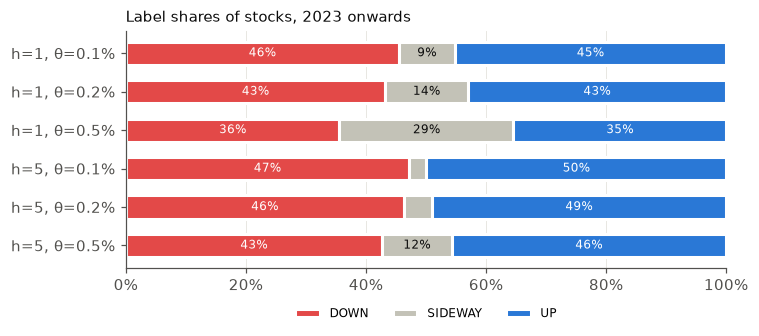

In [13]:
def plot_balance(balance: pd.DataFrame, path) -> None:
    """Draw 100% stacked bars of the label shares for stocks.

    Args:
        balance: Output rows of ``label_shares``.
        path: File the figure is saved to.
    """
    stocks_only = balance[balance["kind"] == "stock"].iloc[::-1]
    names = [f"h={h}, θ={band}%" for h, band
             in zip(stocks_only["h"], stocks_only["band"], strict=True)]
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.set_axisbelow(True)
    left = np.zeros(len(stocks_only))
    for column, color, ink in (("DOWN", DOWN_COLOR, "white"),
                               ("SIDEWAY", FLAT_COLOR, INK),
                               ("UP", UP_COLOR, "white")):
        values = stocks_only[column].to_numpy()
        ax.barh(names, values, left=left, color=color, height=0.6,
                edgecolor="white", linewidth=2, label=column)
        for y, (x0, width) in enumerate(zip(left, values, strict=True)):
            if width > 0.08:
                ax.text(x0 + width / 2, y, f"{width:.0%}", ha="center",
                        va="center", fontsize=8, color=ink)
        left += values
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title("Label shares of stocks, 2023 onwards", loc="left",
                 fontsize=10, color=INK)
    ax.legend(ncol=3, frameon=False, loc="upper center",
              bbox_to_anchor=(0.5, -0.12), fontsize=8)
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_balance(balance, FIGURES / "label_balance.png")

**Reading.** With θ = 0.2%, sideways is a minority class: about 14% of
stock labels and 20% of index labels at h = 1, and only 5–7% at h = 5. Most
of the stock sideways labels at h = 1 are an unchanged close, so they
reflect the tick size more than a "quiet" market.

A band of 0.5% gives a more balanced three-class problem, but it no longer
matches the rule Arena scores against, and it would change the labels the
forward test has been logging since 2026-11-18. **Decision: keep θ = 0.2%.**
The h = 5 sideways class is nearly empty, which supports testing the binary
UP/DOWN variant already planned in `feat/forecaster-v1`.

## 7. Market regimes 2019–2026

`market_state` labels each VNINDEX session as an uptrend, a downtrend or
sideways, based on where the index stands against its 20- and 50-session
averages. This section shows the share of each regime per year and the
largest drawdowns.

In [14]:
def regime_shares(market: pd.DataFrame) -> pd.DataFrame:
    """Share of sessions in each regime per calendar year.

    Args:
        market: Market state with a ``regime`` column, indexed by date.

    Returns:
        Years by regimes.
    """
    regimes = market["regime"].dropna()
    shares = regimes.groupby(regimes.index.year).value_counts(normalize=True)
    return shares.unstack().reindex(
        columns=["uptrend", "sideways", "downtrend"]).fillna(0.0)


def drawdowns(close: pd.Series, top: int = 4) -> pd.DataFrame:
    """Find the deepest peak-to-trough falls of a price series.

    Args:
        close: Prices indexed by date.
        top: Number of drawdowns returned.

    Returns:
        Peak date, trough date and depth in percent, deepest first.
    """
    peak = close.cummax()
    depth = close / peak - 1.0
    episode = (depth == 0).cumsum()
    rows = []
    for _, part in depth.groupby(episode):
        if part.min() < 0:
            trough = part.idxmin()
            rows.append({"peak": part.index[0].date(),
                         "trough": trough.date(),
                         "depth_pct": round(part.min() * 100, 1)})
    table = pd.DataFrame(rows).sort_values("depth_pct")
    return table.head(top).reset_index(drop=True)


market = data.market
print(regime_shares(market).round(2).to_string())
print()
falls = drawdowns(market["idx_close"])
print(falls.to_string())
assert falls["depth_pct"].iloc[0] < -30, falls

regime  uptrend  sideways  downtrend
date                                
2019       0.23      0.58       0.20
2020       0.46      0.29       0.25
2021       0.69      0.28       0.03
2022       0.17      0.42       0.41
2023       0.45      0.38       0.16
2024       0.46      0.36       0.18
2025       0.53      0.41       0.06
2026       0.23      0.48       0.29

         peak      trough  depth_pct
0  2022-01-06  2022-11-15      -40.3
1  2019-11-06  2020-03-24      -35.7
2  2026-01-13  2026-03-23      -16.4
3  2021-01-15  2021-01-28      -14.3


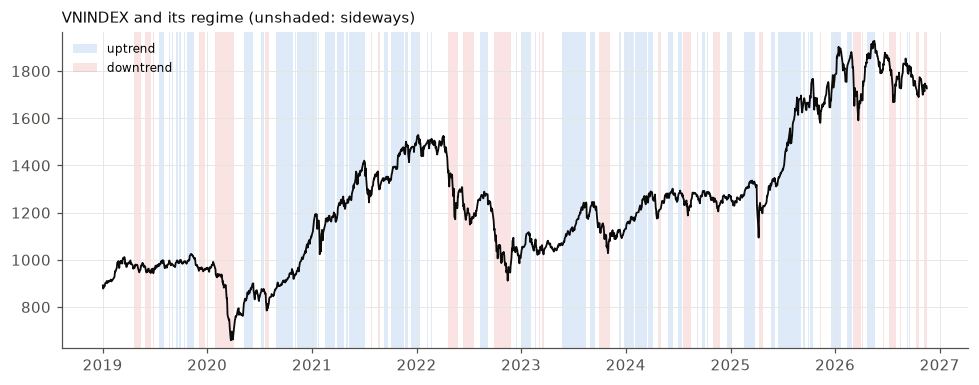

In [15]:
def plot_regimes(market: pd.DataFrame, path) -> None:
    """Draw VNINDEX with uptrend and downtrend sessions shaded.

    Args:
        market: Market state with ``idx_close`` and ``regime``.
        path: File the figure is saved to.
    """
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.plot(market.index, market["idx_close"], color=INK, linewidth=1.2)
    low, high = market["idx_close"].min(), market["idx_close"].max()
    for regime, color in (("uptrend", UP_COLOR),
                          ("downtrend", DOWN_COLOR)):
        ax.fill_between(market.index, low * 0.95, high * 1.02,
                        where=market["regime"] == regime, color=color,
                        alpha=0.15, linewidth=0, label=regime)
    ax.set_ylim(low * 0.95, high * 1.02)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_title("VNINDEX and its regime (unshaded: sideways)", loc="left",
                 fontsize=10, color=INK)
    ax.legend(frameon=False, loc="upper left", fontsize=8)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_regimes(market, FIGURES / "vnindex_regimes.png")

**Reading.** The full history covers every kind of market the model must
handle:
- the COVID crash of early 2020;
- the 2020–2021 retail boom;
- the 2022 bust (the deepest fall);
- the 2023–2025 recovery and the 2026 correction.

A sample starting in 2023 trains only on the recovery years and has not
seen a sustained bear market. Training from 2020 adds the crash, the boom
and the bust.

## 8. Sample start: 2020 or 2023

Train the logistic model from 2020 and from 2023, and score both on
**identical** test blocks. These are the walk-forward folds of the current
setup that end before 2026-06-01, the planned holdout start, so the holdout
stays unseen. The Diebold–Mariano test compares the daily mean log loss of
the two variants (negative statistic: 2020 is better).

In [16]:
HOLDOUT_START = pd.Timestamp("2026-06-01")
MODELS = ["majority", "logistic"]


def dev_folds(horizon: int) -> list:
    """Walk-forward folds of the 2023 sample that end before the holdout.

    Args:
        horizon: Label horizon.

    Returns:
        The folds, in time order.
    """
    wf = settings.walk_forward
    sample = sessions[sessions >= str(settings.data.sample_start)]
    folds = walk_forward_folds(sample, wf.min_train_sessions,
                               wf.test_sessions, horizon,
                               wf.embargo_sessions)
    return [fold for fold in folds if fold.test_end < HOLDOUT_START]


def scored_variant(horizon: int, train_start: pd.Timestamp) -> pd.DataFrame:
    """Score the models with every fold's training starting at one date.

    Args:
        horizon: Label horizon.
        train_start: First training session.

    Returns:
        Scored out-of-sample predictions.
    """
    folds = [dataclasses.replace(fold, train_start=train_start)
             for fold in dev_folds(horizon)]
    panel = data.panel[data.panel["date"] >= train_start]
    oos = walk_forward_predictions(panel, data.feature_cols, horizon,
                                   MODELS, folds, settings)
    return score_rows(oos)


def compare_starts(horizon: int, starts: dict) -> dict:
    """Compare log loss of the logistic model across training starts.

    Args:
        horizon: Label horizon.
        starts: Name to first training session; the first entry is the
            reference.

    Returns:
        Metrics per variant and model, plus the DM statistic and p-value of
        the second variant against the first.
    """
    scored = {name: scored_variant(horizon, start)
              for name, start in starts.items()}
    metrics = pd.concat({
        name: frame.groupby("model")[["correct", "log_loss"]].mean()
        for name, frame in scored.items()
    }, names=["start"]).round(4)
    reference, other = (scored[name][scored[name]["model"] == "logistic"]
                        .set_index(["date", "symbol"])["log_loss"]
                        for name in starts)
    common = reference.index.intersection(other.index)
    diff = (other[common] - reference[common]).groupby(level="date").mean()
    stat, p_value = diebold_mariano(diff, horizon)
    return {"metrics": metrics, "dm": stat, "p": p_value, "rows": len(common)}


starts = {
    "2023": sessions[sessions >= "2023-01-01"][0],
    "2020": sessions[sessions >= "2020-01-01"][0],
}
results = {h: compare_starts(h, starts) for h in settings.labels.horizons}
for h, result in results.items():
    print(f"h={h}: {len(dev_folds(h))} dev folds, {result['rows']:,} "
          f"common predictions; DM 2020 vs 2023 = {result['dm']:.2f}, "
          f"p = {result['p']:.3f}")
    print(result["metrics"].to_string(), end="\n\n")
assert all(r["dm"] < 0 for r in results.values())

h=1: 28 dev folds, 44,708 common predictions; DM 2020 vs 2023 = -1.71, p = 0.087
                correct  log_loss
start model                      
2023  logistic   0.4422    0.9983
      majority   0.4265    1.0047
2020  logistic   0.4423    0.9950
      majority   0.4265    1.0049

h=5: 27 dev folds, 42,920 common predictions; DM 2020 vs 2023 = -1.59, p = 0.111
                correct  log_loss
start model                      
2023  logistic   0.4736    0.8716
      majority   0.4921    0.8578
2020  logistic   0.4788    0.8591
      majority   0.4921    0.8574



**Reading.** Training from 2020 lowers the logistic log loss at both
horizons, and at h = 5 it closes most of the gap to the majority
baseline. The gain is consistent in direction but **not significant at 5%**
(p ≈ 0.09 at h = 1 and 0.11 at h = 5).

**Decision: keep `sample_start: 2023-01-01` for now.** Treat 2020 as the
first variant to test in `feat/forecaster-v1`, where richer models may
benefit more from three extra years. Moving the start now would also change
the forward-test model in its first week for a gain that is not yet
proven. The transfer fix of section 3 is what makes a 2020 start usable.

## 9. Universe

The VN30 list in `config/universe.yaml` had been rebuilt from press
reports and was marked unverified. Following HOSE's review results in
order:

| Effective | Out | In |
|---|---|---|
| 2025-08 | BVH | DGC |
| 2026-02-02 | BCM | VPL |
| 2026-05-13 | DGC | BSR |
| 2026-08-03 | PLX, TPB | MCH, TCX |
| 2026-11-16 | weights only | — |

The old list still had BVH and lacked VPL. It is now corrected and marked
verified.

**Survivorship bias.** The universe is today's VN30, banks and sector
leaders, applied to the whole history. Stocks that left the large-cap group
(for example BCM, DGC, PLX and TPB) are partly or wholly missing from the
earlier years. Backtest results are therefore mildly optimistic: the
universe was picked knowing which firms stayed large. This is recorded as a
threat to validity in the strategy document.

In [17]:
vn30 = set(universe.vn30)
print(f"VN30 members: {len(vn30)}, verified: {universe.vn30_verified}")
print(f"Without Arena bars: {sorted(vn30 - set(raw['symbol']))}")
assert len(vn30) == 30 and "VPL" in vn30 and "BVH" not in vn30

VN30 members: 30, verified: True
Without Arena bars: ['MCH', 'VPL']


## 10. Decisions

| Topic | Decision | Evidence |
|---|---|---|
| Price limits | Use the limit of the exchange the stock traded on that day; ±20% on the first session after a transfer | 14 transfers confirmed in the press (IDC found by the high/low check); suspect moves fall by almost nine in ten (section 3) |
| Unadjusted corporate actions | Keep voiding labels across moves beyond the limit | Arena is back-adjusted for most dividends, but 2021 stock dividends and 2026 TCX/FPT events are not (section 4) |
| Copied bars | Void labels spanning a bar that copies the previous one, and the bar after it | 0.5% of bars, mostly transfer gaps and illiquid UPCoM days (section 5) |
| PNJ, July 2026 | Real sell-off; keep | Limit-down run matches press reports (section 4) |
| Sideways band θ | Keep 0.2% | Matches Arena scoring; h = 5 sideways ≈ 5%, so test a binary variant (section 6) |
| Sample start | Keep 2023; test 2020 in forecaster-v1 | 2020 is better but not significant: p ≈ 0.09 / 0.11 (section 8) |
| VN30 list | Replace BVH with VPL; mark verified | HOSE reviews 2025-08 to 2026-11 (section 9) |
| HNX → HOSE (2026-12-28) | Update once the price limit is published | Mass transfer announced; limit not yet set |